In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

In [ ]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape :", X.shape)
print("Number of Classes :", len(np.unique(y)))

Dataset Shape : (569, 30)
Number of Classes : 2


In [ ]:
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [ ]:
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=5,
        scoring='accuracy'
    )

    results.append([
        name,
        scores.mean(),
        scores.std()
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Mean CV Accuracy",
        "Std Deviation"
    ]
)

print("\nCross Validation Results")
print(results_df)


Cross Validation Results
               Model  Mean CV Accuracy  Std Deviation
0      Random Forest          0.956094       0.022839
1           AdaBoost          0.968374       0.013110
2  Gradient Boosting          0.963127       0.021024


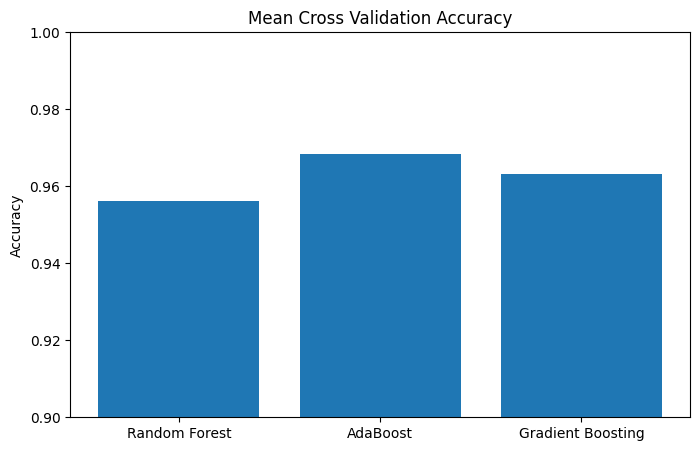

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    results_df["Model"],
    results_df["Mean CV Accuracy"]
)

plt.title("Mean Cross Validation Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0.90,1.00)

plt.show()

In [ ]:
rf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(random_state=42))
])

rf_params = {
    "model__n_estimators":[50,100,200],
    "model__max_depth":[None,5,10],
    "model__min_samples_split":[2,5]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=5,
    scoring="accuracy"
)

rf_grid.fit(X,y)

print("\nRandom Forest")
print("Best Parameters :", rf_grid.best_params_)
print("Best Accuracy :", rf_grid.best_score_)



Random Forest
Best Parameters : {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 50}
Best Accuracy : 0.9631268436578171


In [ ]:
ada_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", AdaBoostClassifier(random_state=42))
])

ada_params = {
    "model__n_estimators":[50,100,200],
    "model__learning_rate":[0.01,0.1,1]
}

ada_grid = GridSearchCV(
    ada_pipeline,
    ada_params,
    cv=5,
    scoring="accuracy"
)

ada_grid.fit(X,y)

print("\nAdaBoost")
print("Best Parameters :", ada_grid.best_params_)
print("Best Accuracy :", ada_grid.best_score_)



AdaBoost
Best Parameters : {'model__learning_rate': 1, 'model__n_estimators': 100}
Best Accuracy : 0.9771619313771154


In [ ]:
gb_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", GradientBoostingClassifier(random_state=42))
])

gb_params = {
    "model__n_estimators":[50,100,200],
    "model__learning_rate":[0.01,0.1,0.2],
    "model__max_depth":[2,3,4]
}

gb_grid = GridSearchCV(
    gb_pipeline,
    gb_params,
    cv=5,
    scoring="accuracy"
)

gb_grid.fit(X,y)

print("\nGradient Boosting")
print("Best Parameters :", gb_grid.best_params_)
print("Best Accuracy :", gb_grid.best_score_)


Gradient Boosting
Best Parameters : {'model__learning_rate': 0.2, 'model__max_depth': 2, 'model__n_estimators': 200}
Best Accuracy : 0.9666200900481291


In [ ]:
best_results = pd.DataFrame({
    "Model":[
        "Random Forest",
        "AdaBoost",
        "Gradient Boosting"
    ],
    "Best Accuracy":[
        rf_grid.best_score_,
        ada_grid.best_score_,
        gb_grid.best_score_
    ]
})

print("\nBest Model Comparison")
print(best_results)


Best Model Comparison
               Model  Best Accuracy
0      Random Forest       0.963127
1           AdaBoost       0.977162
2  Gradient Boosting       0.966620


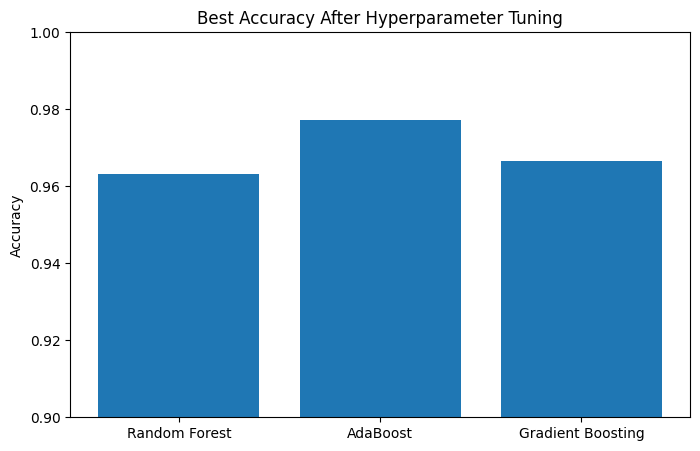

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    best_results["Model"],
    best_results["Best Accuracy"]
)

plt.title("Best Accuracy After Hyperparameter Tuning")
plt.ylabel("Accuracy")
plt.ylim(0.90,1.00)

plt.show()


In [ ]:
best_model = best_results.loc[
    best_results["Best Accuracy"].idxmax()
]

print("\n===================================")
print("Best Performing Model")
print(best_model)
print("===================================")



Best Performing Model
Model            AdaBoost
Best Accuracy    0.977162
Name: 1, dtype: object
